# Análisis territorial

Celdas 1 y 2: carga y funciones

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

BASE      = Path(r"C:\Users\fsociety\Videos\Proyecto_EEVV")
PROCESADO = BASE / "datos" / "procesado"
ORO       = BASE / "datos" / "oro"

defun = pd.read_parquet(PROCESADO / "defunciones_primera_infancia_pacifico.parquet")
nac   = pd.read_parquet(PROCESADO / "nacimientos_pacifico.parquet")
print("Defunciones:", defun.shape, "| Nacimientos:", nac.shape)

Defunciones: (3217, 67) | Nacimientos: (211367, 44)


In [2]:
def tasa_ic(defunciones, nacimientos, por=1000, nivel=0.95):
    a = 1 - nivel
    d = defunciones.astype(float)
    inf = np.where(d > 0, chi2.ppf(a / 2, 2 * d) / 2, 0.0)
    sup = chi2.ppf(1 - a / 2, 2 * (d + 1)) / 2
    return pd.DataFrame({"defunciones": defunciones, "nacimientos": nacimientos,
                         "tasa":   d   / nacimientos * por,
                         "ic_inf": inf / nacimientos * por,
                         "ic_sup": sup / nacimientos * por})

INDICADORES = {
    "Neonatal":                    ["Neonatal"],
    "Posneonatal":                 ["Posneonatal"],
    "Infantil (menores de 1 año)": ["Neonatal", "Posneonatal"],
    "Menores de 5 años":           ["Neonatal", "Posneonatal", "1 a 4 años"],
}

Celda 3: departamentos frente a la región (2022 a 2024 acumulados)

In [3]:
nac_dpto = nac.groupby("dpto_residencia_nombre", observed=True).size()
filas = []
for nombre, grupos in INDICADORES.items():
    sel = defun[defun["grupo_edad_analisis"].isin(grupos)]
    d = sel.groupby("dpto_residencia_nombre", observed=True).size().reindex(nac_dpto.index, fill_value=0)
    t = tasa_ic(d, nac_dpto)
    tasa_region = len(sel) / len(nac) * 1000
    t["tasa_region"] = tasa_region
    t["frente_a_region"] = np.select(
        [t["ic_inf"] > tasa_region, t["ic_sup"] < tasa_region],
        ["Por encima", "Por debajo"], "Similar")
    filas.append(t.assign(indicador=nombre))

tasas_dpto = (pd.concat(filas).reset_index()
              .rename(columns={"dpto_residencia_nombre": "departamento"}))
tasas_dpto.round(1)

,departamento,defunciones,nacimientos,tasa,ic_inf,ic_sup,tasa_region,frente_a_region,indicador
0,Cauca,288,43090,6.7,5.9,7.5,7.2,Similar,Neonatal
1,Chocó,245,19771,12.4,10.9,14.0,7.2,Por encima,Neonatal
2,Nariño,240,38075,6.3,5.5,7.2,7.2,Por debajo,Neonatal
3,Valle del Cauca,751,110431,6.8,6.3,7.3,7.2,Similar,Neonatal
4,Cauca,176,43090,4.1,3.5,4.7,4.8,Por debajo,Posneonatal
5,Chocó,318,19771,16.1,14.4,18.0,4.8,Por encima,Posneonatal
6,Nariño,149,38075,3.9,3.3,4.6,4.8,Por debajo,Posneonatal
7,Valle del Cauca,378,110431,3.4,3.1,3.8,4.8,Por debajo,Posneonatal
8,Cauca,464,43090,10.8,9.8,11.8,12.0,Por debajo,Infantil (menores de 1 año)
9,Chocó,563,19771,28.5,26.2,30.9,12.0,Por encima,Infantil (menores de 1 año)


Celda 4: gráfico departamental

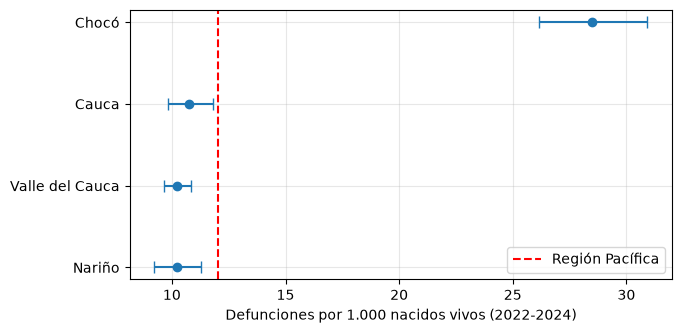

In [4]:
inf_d = tasas_dpto[tasas_dpto["indicador"] == "Infantil (menores de 1 año)"].sort_values("tasa")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(inf_d["tasa"], inf_d["departamento"],
            xerr=[inf_d["tasa"] - inf_d["ic_inf"], inf_d["ic_sup"] - inf_d["tasa"]],
            fmt="o", capsize=4)
ax.axvline(inf_d["tasa_region"].iloc[0], color="red", ls="--", label="Región Pacífica")
ax.set_xlabel("Defunciones por 1.000 nacidos vivos (2022-2024)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Celda 5: municipios con los tres niveles

In [5]:
infantil = defun[defun["grupo_edad_analisis"].isin(["Neonatal", "Posneonatal"])]
claves = ["dpto_residencia_nombre", "mun_residencia_divipola"]

nac_mun = nac.groupby(claves, observed=True).size()
d_mun   = infantil.groupby(claves, observed=True).size().reindex(nac_mun.index, fill_value=0)

tasas_mun = (tasa_ic(d_mun, nac_mun).reset_index()
             .rename(columns={"dpto_residencia_nombre": "departamento",
                              "mun_residencia_divipola": "municipio_cod"}))

tasas_mun["confiabilidad"] = pd.cut(tasas_mun["defunciones"], bins=[-1, 9, 19, np.inf],
                                    labels=["Datos insuficientes", "Usar con precaución", "Confiable"])

insuficiente = tasas_mun["confiabilidad"] == "Datos insuficientes"
tasas_mun.loc[insuficiente, ["tasa", "ic_inf", "ic_sup"]] = np.nan

pd.crosstab(tasas_mun["departamento"], tasas_mun["confiabilidad"], margins=True, margins_name="Total")

confiabilidad,Datos insuficientes,Usar con precaución,Confiable,Total
departamento,,,,
Cauca,25,10,7,42
Chocó,17,5,9,31
Nariño,58,3,3,64
Valle del Cauca,24,10,8,42
Total,124,28,27,179


Celda 6: municipios confiables

In [6]:
confiables = tasas_mun[tasas_mun["confiabilidad"] == "Confiable"].sort_values("tasa", ascending=False)
confiables[["departamento", "municipio_cod", "defunciones", "nacimientos", "tasa", "ic_inf", "ic_sup"]].round(1)

,departamento,municipio_cod,defunciones,nacimientos,tasa,ic_inf,ic_sup
44,Chocó,27025,35,248,141.1,98.3,196.3
48,Chocó,27077,28,230,121.7,80.9,175.9
49,Chocó,27099,30,345,87.0,58.7,124.1
46,Chocó,27073,25,410,61.0,39.5,90.0
70,Chocó,27787,43,714,60.2,43.6,81.1
58,Chocó,27413,27,595,45.4,29.9,66.0
38,Cauca,19809,20,491,40.7,24.9,62.9
56,Chocó,27361,37,1507,24.6,17.3,33.8
42,Chocó,27001,145,6925,20.9,17.7,24.6
67,Chocó,27615,43,2102,20.5,14.8,27.6


Celda 7: gráfico municipal

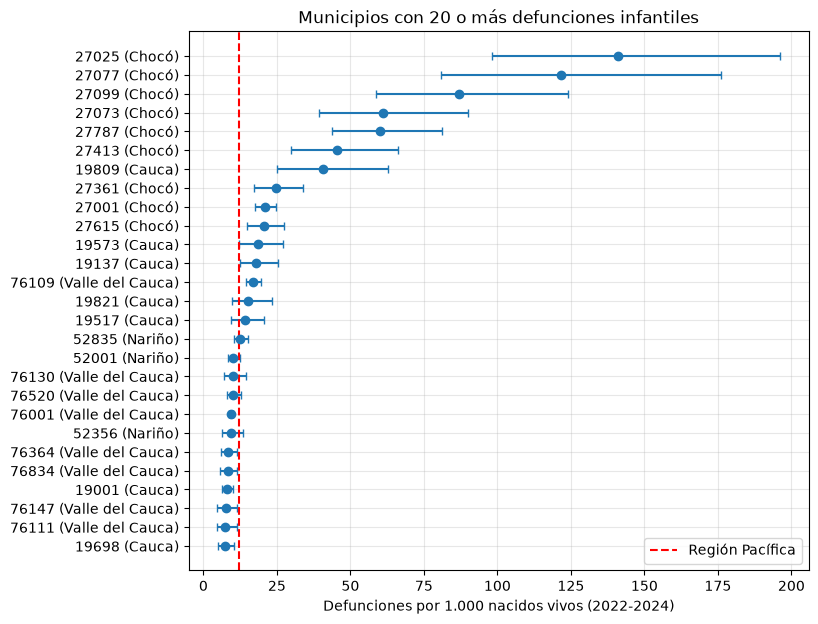

In [7]:
c = confiables.sort_values("tasa")
etiqueta = c["municipio_cod"] + " (" + c["departamento"].astype(str) + ")"

fig, ax = plt.subplots(figsize=(8, 7))
ax.errorbar(c["tasa"], etiqueta, xerr=[c["tasa"] - c["ic_inf"], c["ic_sup"] - c["tasa"]],
            fmt="o", capsize=3)
ax.axvline(inf_d["tasa_region"].iloc[0], color="red", ls="--", label="Región Pacífica")
ax.set_xlabel("Defunciones por 1.000 nacidos vivos (2022-2024)")
ax.set_title("Municipios con 20 o más defunciones infantiles")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Celda 8: guardar en la capa oro

In [8]:
tasas_dpto.to_parquet(ORO / "tasas_departamentales_acumuladas.parquet", index=False)
tasas_mun.to_parquet(ORO / "tasas_municipales_acumuladas.parquet", index=False)
print("Guardado en", ORO)

Guardado en C:\Users\fsociety\Videos\Proyecto_EEVV\datos\oro
